In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.decomposition import PCA
from sklearn.svm._classes import SVR

pd.set_option('display.max_columns', None)

In [1]:
#Tweaked code to return a df instead of np arrays
#Source: https://colab.research.google.com/drive/1LSctTw_0hG4PVmnVUzOWWbisC659-sjx

def getCosmicWatch_df(fname,_BINSIZE_=60,_TIMEOFFSET_=0):
    # output file:
    # [count] [time stamp] [ADC] [SiPM] [deadtime] [temp]
    count,time,coin,adc,sipm,deadt,temp,press = np.genfromtxt(fname=fname,skip_header=6,unpack=True)
    ####
    #### calculate the count rate in chunks of _BINSIZE_ (above)
    ####
    event_deadt = np.diff(np.append([0],deadt))
    # total_time = max(time)
    # total_deadt = max(deadt)
    # #total_counts = max(count)-min(count)
    # total_counts = len(count)

    ## change time from milliseconds to seconds
    time_s = time/1000.
    event_deadt_s = event_deadt/1000.
    #total_time_s = total_time/1000.
    #total_deadt_s = total_deadt/1000.
    event_livetime_s = np.diff(np.append([0],time_s)) - event_deadt_s

    ####
    #### bin the data for nice plots
    ####
    bins = range(int(min(time_s)),int(max(time_s)),_BINSIZE_)
    counts,binEdges = np.histogram(time_s, bins=bins)
    bin_livetime,binEdges = np.histogram(time_s,bins=bins,weights=event_livetime_s)
    
    #print(bin_livetime)

    bincenters = 0.5*(binEdges[1:]+binEdges[:-1])

    #CHANGED to prevent error when bin_livetime is 0, ends up being 0/0 which ERRORS
    
    with np.errstate(divide="ignore", invalid="ignore"):
        binned_count_rate = np.where(bin_livetime > 0, counts / bin_livetime, 0)
        binned_count_rate_err = np.where(
            bin_livetime > 0, np.sqrt(counts) / bin_livetime, 0
        )
    
    binned_time = bincenters/_BINSIZE_
    
    
    #return binned_time+_TIMEOFFSET_,binned_count_rate,binned_count_rate_err


    df = pd.DataFrame(
        {
            "Timestamp_s": bincenters + _TIMEOFFSET_,
            "Counts_Per_Second": binned_count_rate,
            "Rate_Error": binned_count_rate_err,
            "Raw_Counts": counts
        }
    )

    return df






In [3]:
# Further tweaked to return a df that can more easily be combined for analysis

def getCosmicWatch_df(fname, _BINSIZE_=5, _TIMEOFFSET_=0):
    # Read ignoring lines starting with '#' (handles dynamic header sizes automatically)
    try:
        # Load raw numeric data ignoring '#' comment lines
        data = np.genfromtxt(fname=fname, comments='#', invalid_raise=False)
        
        # Guard against empty/unparseable files
        if data.size == 0 or data.ndim < 2:
            print(f"Warning: No valid numeric data found in {fname}")
            return pd.DataFrame(columns=["Timestamp_s", "Counts_Per_Second", "Rate_Error", "Raw_Counts"])
            
    except Exception as e:
        print(f"Error reading {fname}: {e}")
        return pd.DataFrame(columns=["Timestamp_s", "Counts_Per_Second", "Rate_Error", "Raw_Counts"])

    # Flexibly extract time (col 1) and deadtime (col 4 or 5 depending on format)
    # Col 0: Count/Event | Col 1: Timestamp (ms or s) | Col 4/5: Deadtime
    time_s = data[:, 1]
    temp = data[:,6]
    press = data[:,7]
    deadt_s = data[:, 5]  # Adjust to 5 if your files log deadtime in column 6

    #time_s = time / 1000.0
    #deadt_s = deadt / 1000.0


    # Calculate live time
    event_deadt_s = np.diff(np.append([0], deadt_s))
    event_livetime_s = np.diff(np.append([0], time_s)) - event_deadt_s

    # Construct bins
    t_min = np.min(time_s)
    t_max = np.max(time_s)
    
    bins = np.arange(t_min, t_max + _BINSIZE_, _BINSIZE_)
    if len(bins) < 2:
        bins = np.array([t_min, t_min + _BINSIZE_])

    counts, binEdges = np.histogram(time_s, bins=bins)
    bin_livetime, _ = np.histogram(time_s, bins=bins, weights=event_livetime_s)

    bincenters = 0.5 * (binEdges[1:] + binEdges[:-1])

    bin_temp_sum, _ = np.histogram(time_s, bins=bins, weights=temp)
    bin_press_sum, _ = np.histogram(time_s, bins=bins, weights=press)

    # Calculate averages per bin using Raw_Counts (muon count per bin)
    # np.where handles empty bins safely by returning NaN instead of dividing by 0
    events_per_bin, _ = np.histogram(time_s, bins=bins)

    # Calculate true arithmetic averages per bin by dividing sum of values by event frequency
    with np.errstate(divide="ignore", invalid="ignore"):
        avg_temp = np.where(events_per_bin > 0, bin_temp_sum / events_per_bin, np.nan)
        avg_press = np.where(events_per_bin > 0, bin_press_sum / events_per_bin, np.nan)
    
    with np.errstate(divide="ignore", invalid="ignore"):
        
        
        binned_count_rate = np.where(bin_livetime > 0, counts / bin_livetime, 0)
        binned_count_rate_err = np.where(
            bin_livetime > 0, np.sqrt(counts) / bin_livetime, 0
        )

    df = pd.DataFrame(
        {
            "Pressure" : avg_press,
            "Temp" : avg_temp,
            "Timestamp_s": bincenters + _TIMEOFFSET_,
            "Counts_Per_Second": binned_count_rate,
            "Rate_Error": binned_count_rate_err,
            "Raw_Counts": counts
        }
    )
    
    return df

In [4]:
mar28_df = pd.read_csv('STAR\Data\Pre-Everything CSV\Mar28-26-DataLogger.csv')
mar28_cw = getCosmicWatch_df('STAR/Data/Mar28/TopScint.txt')
mar28_cw

,Pressure,Temp,Timestamp_s,Counts_Per_Second,Rate_Error,Raw_Counts
0,101915.363636,8.000000,3.073987,1.988344,0.599508,11
1,101915.666667,8.075000,8.073987,2.518608,0.727060,12
2,101914.000000,8.150000,13.073987,1.562886,0.552564,8
3,101913.636364,8.372727,18.073987,2.632141,0.793620,11
4,101932.333333,8.683333,23.073987,1.304331,0.532491,6
...,...,...,...,...,...,...
4157,101644.600000,38.320000,20788.073987,2.521472,0.651041,15
4158,101647.818182,36.663636,20793.073987,2.912898,0.878272,11
4159,101650.000000,34.245455,20798.073987,1.868079,0.563247,11
4160,101651.166667,32.527778,20803.073987,4.081941,0.962123,18


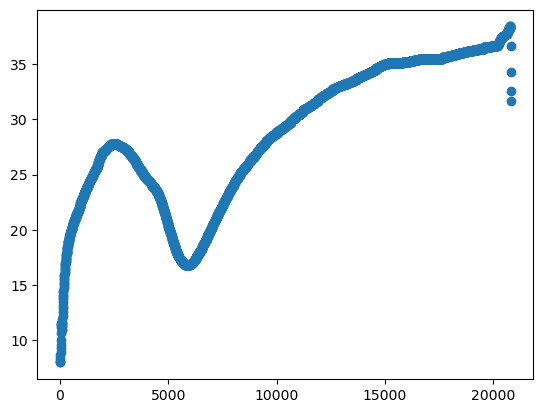

In [5]:
plt.scatter(mar28_cw['Timestamp_s'],mar28_cw['Temp'])

In [6]:
time_col = 'RTC[H:M:S EST]'

mar28_df['Mag'] = np.sqrt(mar28_df['Mag x']**2 + mar28_df['Mag y']**2 + mar28_df['Mag z']**2)
mar28_df['Accel'] = np.sqrt(mar28_df['Accel x']**2 + mar28_df['Accel y']**2 + mar28_df['Accel z']**2)

s = mar28_df[time_col].astype(str).str.split().str[-1]
s_clean = s.apply(
    lambda t: ":".join(
        part.zfill(2) if i < 2 else part for i, part in enumerate(t.split(":"))
    )
)

mar28_df["duration"] = pd.to_timedelta(s_clean)
mar28_df["elapsed_seconds"] = (
    mar28_df["duration"] - mar28_df["duration"].iloc[0]
).dt.total_seconds()

#mar28_df["elapsed_time"] = (mar28_df[time_col] - mar28_df[time_col].iloc[0]).dt.total_seconds()


mar28_df

,Events CW1&2,Events CW1&2&3,Temperature[C],Pressure[Pa],Date[MM/DD/YYYY],RTC[H:M:S EST],Timer[S],Latitude,Longitude,Altitude[m],Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Mag x,Mag y,Mag z,Battery[],Mag,Accel,duration,elapsed_seconds
0,1,0,12.71,101845.17,3/28/2026,11:16:40.206,46.691406,0.00000,0.00000,0.0,0,-3.35593,9.26621,0.05982,0.01588,0.17837,-0.02077,-37.73750,25.50424,-83.13358,86,94.793340,9.855379,0 days 11:16:40.206000,0.000
1,1,1,12.71,101845.17,3/28/2026,11:16:40.206,46.700195,0.00000,0.00000,0.0,0,-3.35593,9.26621,0.05982,0.01588,0.17837,-0.02077,-37.73750,25.50424,-83.13358,86,94.793340,9.855379,0 days 11:16:40.206000,0.000
2,2,1,12.72,101847.44,3/28/2026,11:16:40.324,46.809570,0.00000,0.00000,0.0,0,-4.17548,9.09033,-0.24168,0.06231,0.07575,-0.21258,-37.29903,26.45425,-81.59895,86,93.538407,10.006355,0 days 11:16:40.324000,0.118
3,2,2,12.72,101847.44,3/28/2026,11:16:40.324,46.818359,0.00000,0.00000,0.0,0,-4.17548,9.09033,-0.24168,0.06231,0.07575,-0.21258,-37.29903,26.45425,-81.59895,86,93.538407,10.006355,0 days 11:16:40.324000,0.118
4,3,2,12.70,101850.70,3/28/2026,11:16:40.676,47.502929,0.00000,0.00000,0.0,0,-3.21356,8.68236,-0.67119,0.02077,-0.15760,0.48625,-37.19672,25.82578,-82.68050,86,94.268934,9.282286,0 days 11:16:40.676000,0.470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43708,25639,18070,29.12,101547.16,3/28/2026,17:2:42.099,3586.824175,39.90889,-75.52424,207.9,12,-3.15972,1.15214,-9.49352,0.04032,-0.06597,0.00489,10.14323,90.04677,-163.49020,33,186.923384,10.071652,0 days 17:02:42.099000,20761.893
43709,25640,18070,29.06,101543.61,3/28/2026,17:2:42.368,3587.069292,39.90889,-75.52424,207.9,12,-3.28056,1.28973,-9.33201,-0.01100,-0.02688,0.03054,9.47091,90.48523,-163.66559,33,187.253038,9.975565,0 days 17:02:42.368000,20762.162
43710,25641,18070,28.70,101543.47,3/28/2026,17:2:45.448,3590.549761,39.90898,-75.52434,210.5,9,-2.82712,1.89631,-9.19921,0.02077,-0.04032,0.00733,10.58170,94.41683,-150.51154,32,177.989421,9.808877,0 days 17:02:45.448000,20765.242
43711,25642,18070,28.58,101541.80,3/28/2026,17:2:46.166,3591.429644,39.90899,-75.52438,211.6,9,-2.41914,2.32702,-9.26022,-0.08796,-0.05131,-0.02443,13.12482,97.22303,-142.18065,32,172.742339,9.849819,0 days 17:02:46.166000,20765.960


In [7]:
#Many of the times have single digits, eg 17:2 instead of 17:02 which pd can't recognize as a time, so fix that
#Also elapsed seconds better than time format, make a column for it

def clean_time_format(df,time_col):
    
    #clean magnetic as well
    df['Mag'] = np.sqrt(df['Mag x']**2 + df['Mag y']**2 + df['Mag z']**2)
    df['Accel'] = np.sqrt(df['Accel x']**2 + df['Accel y']**2 + df['Accel z']**2)

    
    s = df[time_col].astype(str).str.split().str[-1]
    s_clean = s.apply(
        lambda t: ":".join(
            part.zfill(2) if i < 2 else part for i, part in enumerate(t.split(":"))
        )
    )
    
    df["duration"] = pd.to_timedelta(s_clean)
    df["elapsed_seconds"] = (
        df["duration"] - df["duration"].iloc[0]
    ).dt.total_seconds()
    return df

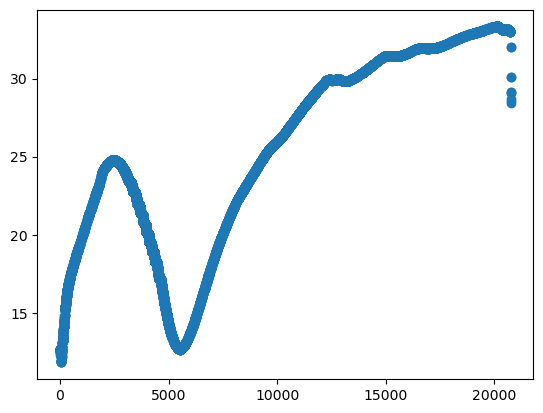

In [8]:
plt.scatter(mar28_df['elapsed_seconds'],mar28_df['Temperature[C]'])

In [9]:
mar28_df

,Events CW1&2,Events CW1&2&3,Temperature[C],Pressure[Pa],Date[MM/DD/YYYY],RTC[H:M:S EST],Timer[S],Latitude,Longitude,Altitude[m],Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Mag x,Mag y,Mag z,Battery[],Mag,Accel,duration,elapsed_seconds
0,1,0,12.71,101845.17,3/28/2026,11:16:40.206,46.691406,0.00000,0.00000,0.0,0,-3.35593,9.26621,0.05982,0.01588,0.17837,-0.02077,-37.73750,25.50424,-83.13358,86,94.793340,9.855379,0 days 11:16:40.206000,0.000
1,1,1,12.71,101845.17,3/28/2026,11:16:40.206,46.700195,0.00000,0.00000,0.0,0,-3.35593,9.26621,0.05982,0.01588,0.17837,-0.02077,-37.73750,25.50424,-83.13358,86,94.793340,9.855379,0 days 11:16:40.206000,0.000
2,2,1,12.72,101847.44,3/28/2026,11:16:40.324,46.809570,0.00000,0.00000,0.0,0,-4.17548,9.09033,-0.24168,0.06231,0.07575,-0.21258,-37.29903,26.45425,-81.59895,86,93.538407,10.006355,0 days 11:16:40.324000,0.118
3,2,2,12.72,101847.44,3/28/2026,11:16:40.324,46.818359,0.00000,0.00000,0.0,0,-4.17548,9.09033,-0.24168,0.06231,0.07575,-0.21258,-37.29903,26.45425,-81.59895,86,93.538407,10.006355,0 days 11:16:40.324000,0.118
4,3,2,12.70,101850.70,3/28/2026,11:16:40.676,47.502929,0.00000,0.00000,0.0,0,-3.21356,8.68236,-0.67119,0.02077,-0.15760,0.48625,-37.19672,25.82578,-82.68050,86,94.268934,9.282286,0 days 11:16:40.676000,0.470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43708,25639,18070,29.12,101547.16,3/28/2026,17:2:42.099,3586.824175,39.90889,-75.52424,207.9,12,-3.15972,1.15214,-9.49352,0.04032,-0.06597,0.00489,10.14323,90.04677,-163.49020,33,186.923384,10.071652,0 days 17:02:42.099000,20761.893
43709,25640,18070,29.06,101543.61,3/28/2026,17:2:42.368,3587.069292,39.90889,-75.52424,207.9,12,-3.28056,1.28973,-9.33201,-0.01100,-0.02688,0.03054,9.47091,90.48523,-163.66559,33,187.253038,9.975565,0 days 17:02:42.368000,20762.162
43710,25641,18070,28.70,101543.47,3/28/2026,17:2:45.448,3590.549761,39.90898,-75.52434,210.5,9,-2.82712,1.89631,-9.19921,0.02077,-0.04032,0.00733,10.58170,94.41683,-150.51154,32,177.989421,9.808877,0 days 17:02:45.448000,20765.242
43711,25642,18070,28.58,101541.80,3/28/2026,17:2:46.166,3591.429644,39.90899,-75.52438,211.6,9,-2.41914,2.32702,-9.26022,-0.08796,-0.05131,-0.02443,13.12482,97.22303,-142.18065,32,172.742339,9.849819,0 days 17:02:46.166000,20765.960


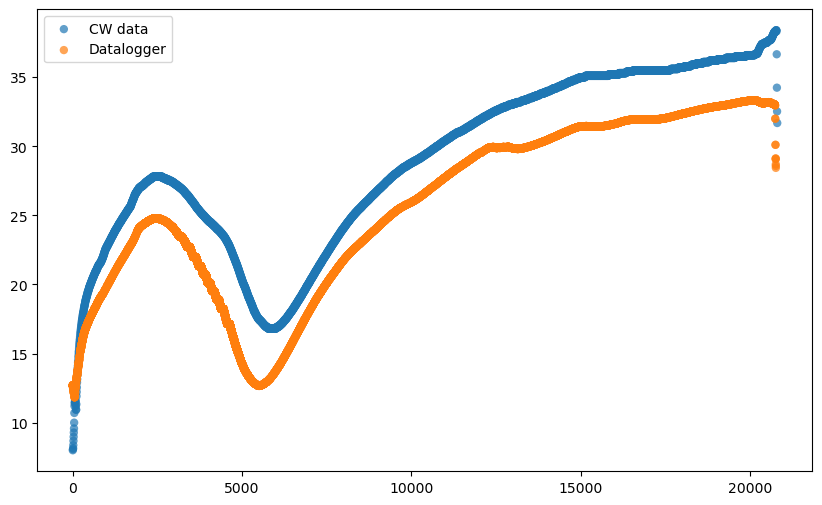

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(mar28_cw['Timestamp_s'], mar28_cw['Temp'], color='tab:blue', label='CW data', alpha=0.7, edgecolors='none')
ax.scatter(mar28_df['elapsed_seconds'], mar28_df['Temperature[C]'], color='tab:orange', label='Datalogger', alpha=0.7, edgecolors='none')
ax.legend()
plt.savefig('mar28temp.png')
plt.show()


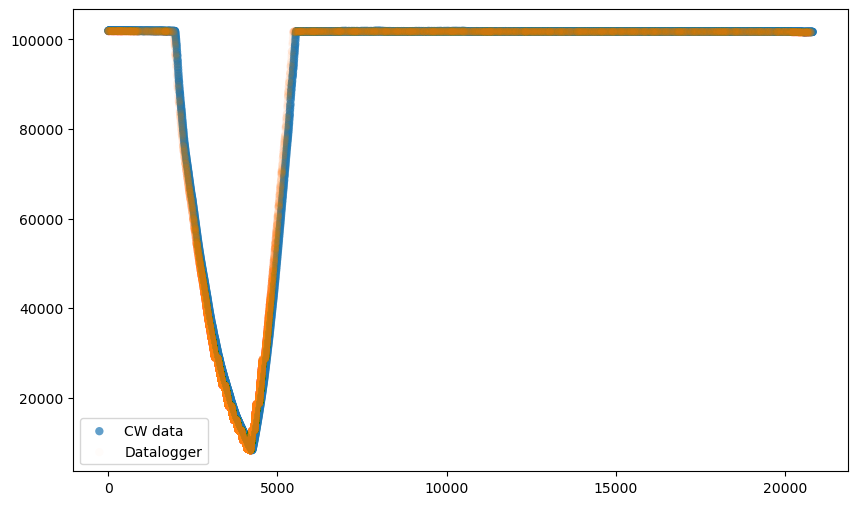

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(mar28_cw['Timestamp_s'], mar28_cw['Pressure'], color='tab:blue', label='CW data', alpha=0.7, edgecolors='none')
ax.scatter(mar28_df['elapsed_seconds'], mar28_df['Pressure[Pa]'], color='tab:orange', label='Datalogger', alpha=0.02, edgecolors='none')
ax.legend()
plt.savefig('mar28press.png')
plt.show()

Start of Analysis

Note to self: use clean_time_format(df,time_col) on datalogger. Then def getCosmicWatch_df(fname) on cw txt file. Then combine_df_cw(df1,df2,df1time,df2time,df2count) where df1 is the datalogger, df2 CW

Then set X and y, then use rfr_report(X,y)

Mar 28

In [12]:
#Obv the cw bins don't align exactly with datalogger observations, so choose one unique datalogger row to place the cw data based on which time is closest
#df1 datalogger, df2 cw

def combine_df_cw(df1,df2,df2time="Timestamp_s",df2count='Counts_Per_Second',df1time='elapsed_seconds'):
    df1 = df1.sort_values(by=[df1time])
    res_df = pd.merge_asof(
        df1,
        df2[[df2count,df2time]],  # Pass only the time and desired column from df2
        left_on=df1time,
        right_on=df2time,
        direction="nearest"
    )
    
    res_df["time_diff"] = (res_df[df1time] - res_df[df2time]).abs()
    res_df = res_df.sort_values("time_diff")
    res_df = res_df.drop_duplicates(subset=[df2time], keep="first")
    res_df = res_df.drop(columns=["time_diff"]).sort_values(df1time)
    res_df = res_df.reset_index(drop=True)
    
    return res_df
    
    


In [13]:
#Code to fit model + print scores, etc faster
def rfr_report(X,y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = Pipeline(steps=[
        ('scaler', StandardScaler()),
        ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
    
    importances = model.named_steps['regressor'].feature_importances_
    
    
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False)
    
    print("\n--- Feature Importances ---")
    print(importance_df.to_string(index=False))

In [14]:
mar28_analysis = combine_df_cw(mar28_df,mar28_cw)
mar28_analysis

,Events CW1&2,Events CW1&2&3,Temperature[C],Pressure[Pa],Date[MM/DD/YYYY],RTC[H:M:S EST],Timer[S],Latitude,Longitude,Altitude[m],Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Mag x,Mag y,Mag z,Battery[],Mag,Accel,duration,elapsed_seconds,Counts_Per_Second,Timestamp_s
0,5,3,12.67,101839.15,3/28/2026,11:16:44.121,50.595703,0.00000,0.00000,0.0,0,-1.81256,10.51885,-2.68953,0.48747,0.21258,0.24068,-45.36685,20.46185,-75.57732,87,90.491821,11.007504,0 days 11:16:44.121000,3.915,1.988344,3.073987
1,13,5,12.64,101838.70,3/28/2026,11:16:48.360,54.820312,0.00000,0.00000,0.0,0,-1.45005,7.55175,-6.08973,0.03787,-0.09041,-0.01955,-44.97223,26.35194,-66.38409,87,84.402450,9.808995,0 days 11:16:48.360000,8.154,2.518608,8.073987
2,20,6,12.63,101823.23,3/28/2026,11:16:53.431,60.203125,0.00000,0.00000,0.0,0,1.25384,2.37009,-8.38924,0.39951,0.32132,-0.05742,-63.68021,38.01520,-53.23005,86,91.289445,8.807315,0 days 11:16:53.431000,13.225,1.562886,13.073987
3,22,6,12.70,101819.53,3/28/2026,11:16:57.453,64.192382,0.00000,0.00000,0.0,0,0.38405,3.15015,-8.02553,0.30299,0.08919,-0.27245,-62.45250,37.97135,-52.23619,86,89.837396,8.630184,0 days 11:16:57.453000,17.247,2.632141,18.073987
4,29,6,12.20,101822.88,3/28/2026,11:17:04.000,70.674804,40.19768,-77.18332,133.4,6,4.27717,4.55593,-7.61635,-0.44471,-0.34575,-0.12706,-74.04268,30.12277,-54.12160,85,96.534177,9.851876,0 days 11:17:04,23.794,1.304331,23.073987
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3289,25636,18066,32.96,101539.95,3/28/2026,17:2:25.404,3570.539995,39.90879,-75.52444,208.3,13,1.68096,9.04726,4.27119,0.82955,0.20892,-0.66829,-60.55247,-1.41771,-93.42297,32,111.339404,10.145029,0 days 17:02:25.404000,20745.198,2.328384,20743.073987
3290,25637,18067,32.00,101545.02,3/28/2026,17:2:29.439,3574.582964,39.90880,-75.52445,207.9,12,0.36251,8.27438,-5.33958,0.04398,-0.07941,-0.00733,-53.25928,6.98626,-52.86466,32,75.365980,9.854334,0 days 17:02:29.439000,20749.233,3.267675,20748.073987
3291,25638,18069,30.11,101548.78,3/28/2026,17:2:36.374,3581.708941,39.90883,-75.52433,204.8,13,1.10668,5.51546,-6.41875,0.70494,0.92607,-0.49114,-73.82344,25.29962,22.96112,33,81.346076,8.534951,0 days 17:02:36.374000,20756.168,2.306920,20758.073987
3292,25640,18070,29.06,101543.61,3/28/2026,17:2:42.368,3587.069292,39.90889,-75.52424,207.9,12,-3.28056,1.28973,-9.33201,-0.01100,-0.02688,0.03054,9.47091,90.48523,-163.66559,33,187.253038,9.975565,0 days 17:02:42.368000,20762.162,3.174682,20763.073987


In [15]:
X = mar28_analysis[['Temperature[C]','Pressure[Pa]','Latitude','Longitude','Altitude[m]','Accel','Mag']]
y = mar28_analysis['Counts_Per_Second']
rfr_report(X,y)

R² Score: 0.9830
RMSE: 1.0943

--- Feature Importances ---
       Feature  Importance
   Altitude[m]    0.978300
     Longitude    0.004615
Temperature[C]    0.004378
      Latitude    0.003670
         Accel    0.003359
           Mag    0.002906
  Pressure[Pa]    0.002772


Oct 4

In [16]:
oct4_df = pd.read_csv('STAR/Data/Oct4/Claire/AHD009.csv')
oct4_df = oct4_df[oct4_df['Date[MM/DD/YYYY]'] == '10/4/2025']
oct4_df = clean_time_format(oct4_df,'RTC[H:M:S EST]')

oct4_cw = getCosmicWatch_df('STAR/Data/Oct4/Claire/AxLab_M_011.txt')

oct4_analysis = combine_df_cw(oct4_df,oct4_cw) 

X = oct4_analysis[['Temperature[C]','Pressure[Pa]','Latitude','Longitude','Altitude[m]','Accel','Mag']]
y = oct4_analysis['Counts_Per_Second']

rfr_report(X,y)

R² Score: 0.9858
RMSE: 2.1119

--- Feature Importances ---
       Feature  Importance
   Altitude[m]    0.961750
  Pressure[Pa]    0.028338
Temperature[C]    0.003805
         Accel    0.002566
           Mag    0.002177
      Latitude    0.000692
     Longitude    0.000672


In [17]:
jun1_df = pd.read_csv('STAR/Data/Jun1/Bravo CW Datalogger Coincident.csv')
jun1_df = jun1_df[jun1_df['Latitude'] != 0]
jun1_df = clean_time_format(jun1_df,'RTC[H:M:S EST]')

jun1_cw = getCosmicWatch_df('STAR/Data/Jun1/Bravo CW Top(1).txt')

jun1_analysis = combine_df_cw(jun1_df,jun1_cw) 

X = jun1_analysis[['Temperature[C]','Pressure[Pa]','Latitude','Longitude','Altitude[m]','Accel','Mag']]
y = jun1_analysis['Counts_Per_Second']

rfr_report(X,y)


R² Score: 0.9850
RMSE: 1.2890

--- Feature Importances ---
       Feature  Importance
  Pressure[Pa]    0.716405
   Altitude[m]    0.266615
      Latitude    0.004382
     Longitude    0.004274
           Mag    0.003264
         Accel    0.003039
Temperature[C]    0.002020


In [18]:
X = jun1_analysis[['Temperature[C]','Pressure[Pa]','Latitude','Longitude','Altitude[m]','Accel','Mag','Counts_Per_Second']]

scaler = StandardScaler()
pca = PCA(n_components=3)
X_scaled = scaler.fit_transform(X)
# Choose top components
pca.fit(X_scaled)

loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    columns=[f'PC{i+1}' for i in range(pca.n_components_)],
    index=X.columns
)

loadings['Overall_Importance'] = loadings.abs().sum(axis=1)

importance_df = loadings.sort_values(by='Overall_Importance', ascending=False)
print(importance_df)

#Principal component analysis (not used in STAR)

                        PC1       PC2       PC3  Overall_Importance
Temperature[C]     0.374820 -0.739972 -0.390250            1.505041
Longitude          0.100560  0.694213 -0.592606            1.387379
Pressure[Pa]       0.942587  0.198278  0.148208            1.289072
Mag               -0.321239  0.097913  0.846710            1.265863
Altitude[m]       -0.941505 -0.104600 -0.194318            1.240424
Counts_Per_Second -0.921258 -0.117978 -0.182525            1.221761
Latitude          -0.114284  0.938612 -0.041260            1.094156
Accel             -0.342430  0.139578  0.051565            0.533573


In [19]:
X = oct4_analysis[['Temperature[C]','Pressure[Pa]','Latitude','Longitude','Altitude[m]','Accel','Gyro x','Gyro y','Gyro z','Mag','Counts_Per_Second']]
scaler = StandardScaler()
pca = PCA(n_components=3)
X_scaled = scaler.fit_transform(X)
pca.fit(X_scaled)

loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    columns=[f'PC{i+1}' for i in range(pca.n_components_)],
    index=X.columns
)
loadings['Overall_Importance'] = loadings.abs().sum(axis=1)
importance_df = loadings.sort_values(by='Overall_Importance', ascending=False)
print(importance_df)

                        PC1       PC2       PC3  Overall_Importance
Longitude         -0.506362  0.639490  0.430702            1.576554
Pressure[Pa]       0.873674  0.333637  0.249134            1.456444
Altitude[m]       -0.872909 -0.345225 -0.231192            1.449326
Counts_Per_Second -0.857231 -0.357117 -0.208838            1.423185
Temperature[C]     0.868632 -0.334139 -0.207213            1.409985
Latitude           0.859199 -0.189854 -0.247649            1.296702
Gyro x            -0.099809  0.616769 -0.570128            1.286706
Gyro z             0.076775 -0.506114  0.608266            1.191155
Mag               -0.355270  0.393427  0.368205            1.116902
Gyro y             0.000172 -0.318837  0.507325            0.826334
Accel             -0.314868 -0.376197 -0.125424            0.816489


In [20]:
X = mar28_analysis[['Temperature[C]','Pressure[Pa]','Latitude','Longitude','Altitude[m]','Accel','Gyro x','Gyro y','Gyro z','Mag','Counts_Per_Second']]
scaler = StandardScaler()
pca = PCA(n_components=3)
X_scaled = scaler.fit_transform(X)
pca.fit(X_scaled)

loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    columns=[f'PC{i+1}' for i in range(pca.n_components_)],
    index=X.columns
)

loadings['Overall_Importance'] = loadings.abs().sum(axis=1)

importance_df = loadings.sort_values(by='Overall_Importance', ascending=False)
print(importance_df)

                        PC1       PC2       PC3  Overall_Importance
Longitude         -0.119888 -0.987704 -0.020462            1.128054
Latitude           0.058037  0.996017  0.009749            1.063803
Altitude[m]        0.967904 -0.024891  0.060776            1.053571
Pressure[Pa]      -0.962296  0.018981 -0.057943            1.039221
Counts_Per_Second  0.878964 -0.035116  0.056475            0.970555
Gyro y            -0.130061  0.001133  0.769291            0.900485
Mag               -0.656108  0.123948 -0.102168            0.882224
Gyro x            -0.149404 -0.026727  0.701471            0.877603
Accel              0.503950  0.004076  0.042278            0.550304
Temperature[C]    -0.374512  0.073527  0.065184            0.513223
Gyro z            -0.060985  0.000581  0.431454            0.493021


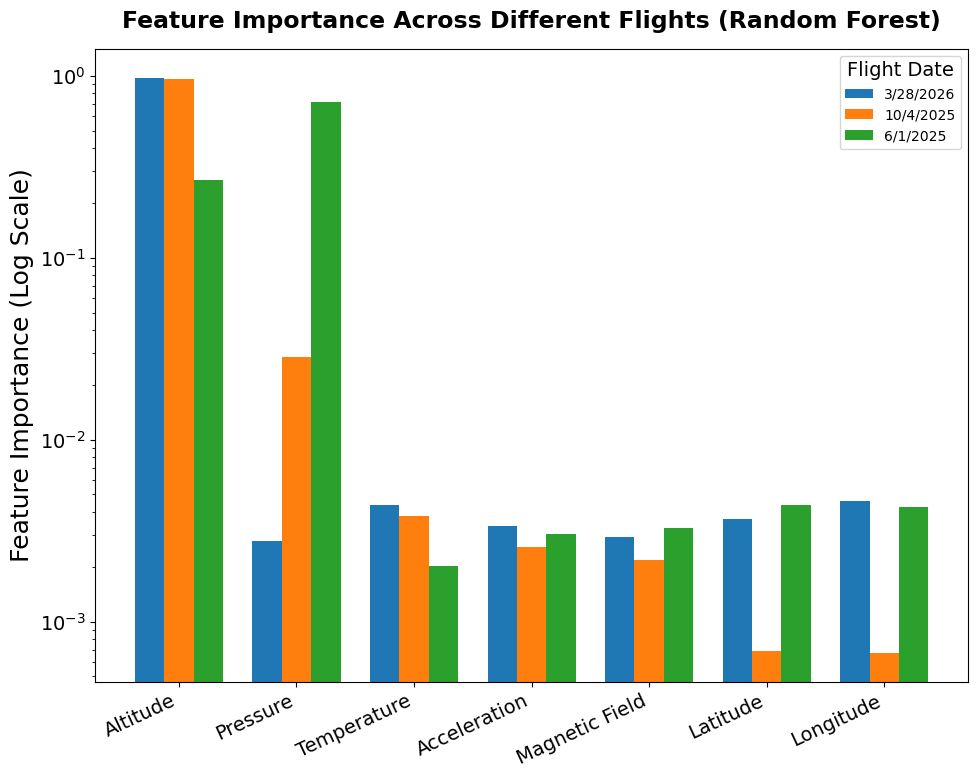

In [21]:
plt.rcParams.update({"font.size": 14})

features = ['Altitude', 'Pressure', 'Temperature', 'Acceleration', 'Magnetic Field', 'Latitude', 'Longitude']
arr1 = [0.978300, 0.002772, 0.004378, 0.003359, 0.002906, 0.003670, 0.004615]
arr2 = [0.961750, 0.028338, 0.003805, 0.002566, 0.002177, 0.000692, 0.000672]
arr3 = [0.266615, 0.716405, 0.002020, 0.003039, 0.003264, 0.004382, 0.004274]


flight_dates = ['3/28/2026', '10/4/2025', '6/1/2025']

x = np.arange(len(features)) 
width = 0.25 

fig, ax = plt.subplots(figsize=(10, 8))

ax.bar(x - width, arr1, width, label=flight_dates[0], color='#1f77b4')
ax.bar(x,         arr2, width, label=flight_dates[1], color='#ff7f0e')
ax.bar(x + width, arr3, width, label=flight_dates[2], color='#2ca02c')

ax.set_yscale('log')

ax.set_ylabel("Feature Importance (Log Scale)", fontsize=18)
ax.set_title(
    "Feature Importance Across Different Flights (Random Forest)",
    fontsize=17,
    fontweight="bold",
    pad=15,
)

ax.set_xticks(x)
ax.set_xticklabels(
    features, fontsize=14, rotation=25, ha="right"
) 


ax.tick_params(axis="y", labelsize=14)

ax.legend(
    title="Flight Date",
    fontsize=14,
    title_fontsize=16,
    loc="upper right",
)

ax.legend(title='Flight Date', fontsize=10)
ax.grid(axis='y', which='both', linestyle='--', alpha=0)

plt.tight_layout()
plt.savefig('feature_importance_rfr.png')

In [22]:
#Code to fit model + print scores, etc faster
def gbr_report(X,y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = Pipeline(steps=[
        ('scaler', StandardScaler()),
        ('regressor', GradientBoostingRegressor(random_state=42))
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
    
    importances = model.named_steps['regressor'].feature_importances_
    
    
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False)
    
    print("\n--- Feature Importances ---")
    print(importance_df.to_string(index=False))

In [23]:
X = mar28_analysis[['Temperature[C]','Pressure[Pa]','Latitude','Longitude','Altitude[m]','Accel','Mag']]
y = mar28_analysis['Counts_Per_Second']
gbr_report(X,y)

R² Score: 0.9827
RMSE: 1.1045

--- Feature Importances ---
       Feature  Importance
   Altitude[m]    0.976427
  Pressure[Pa]    0.010297
Temperature[C]    0.006802
     Longitude    0.004016
      Latitude    0.001209
         Accel    0.000707
           Mag    0.000542


In [24]:
X = oct4_analysis[['Temperature[C]','Pressure[Pa]','Latitude','Longitude','Altitude[m]','Accel','Mag']]
y = oct4_analysis['Counts_Per_Second']
gbr_report(X,y)

R² Score: 0.9867
RMSE: 2.0477

--- Feature Importances ---
       Feature  Importance
   Altitude[m]    0.967912
  Pressure[Pa]    0.027180
Temperature[C]    0.003035
         Accel    0.000836
           Mag    0.000376
      Latitude    0.000358
     Longitude    0.000303


In [25]:
X = jun1_analysis[['Temperature[C]','Pressure[Pa]','Latitude','Longitude','Altitude[m]','Accel','Mag']]
y = jun1_analysis['Counts_Per_Second']
gbr_report(X,y)

R² Score: 0.9854
RMSE: 1.2720

--- Feature Importances ---
       Feature  Importance
  Pressure[Pa]    0.884754
   Altitude[m]    0.108171
           Mag    0.002345
     Longitude    0.002039
Temperature[C]    0.000955
      Latitude    0.000945
         Accel    0.000791


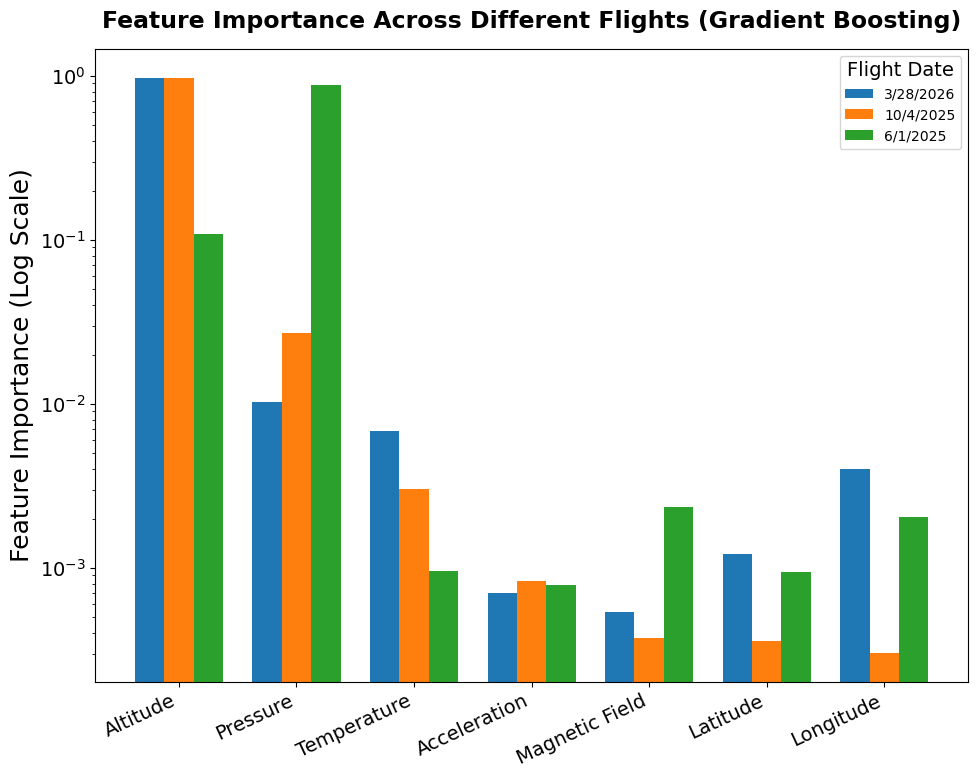

In [26]:
features = ['Altitude', 'Pressure', 'Temperature', 'Acceleration', 'Magnetic Field', 'Latitude', 'Longitude']

arr1 = [0.976427, 0.010297, 0.006802, 0.000707, 0.000542, 0.001209, 0.004016]
arr2 = [0.967912, 0.027180, 0.003035, 0.000836, 0.000376, 0.000358, 0.000303]
arr3 = [0.108171, 0.884754, 0.000955, 0.000791, 0.002345, 0.000945, 0.002039]

flight_dates = ['3/28/2026', '10/4/2025', '6/1/2025']


x = np.arange(len(features))  
width = 0.25                 

fig, ax = plt.subplots(figsize=(10, 8))

ax.bar(x - width, arr1, width, label=flight_dates[0], color='#1f77b4')
ax.bar(x,         arr2, width, label=flight_dates[1], color='#ff7f0e')
ax.bar(x + width, arr3, width, label=flight_dates[2], color='#2ca02c')

ax.set_yscale('log')


ax.set_ylabel("Feature Importance (Log Scale)", fontsize=18)
ax.set_title(
    "Feature Importance Across Different Flights (Gradient Boosting)",
    fontsize=17,
    fontweight="bold",
    pad=15,
)

ax.set_xticks(x)
ax.set_xticklabels(
    features, fontsize=14, rotation=25, ha="right"
)  


ax.tick_params(axis="y", labelsize=14)

ax.legend(
    title="Flight Date",
    fontsize=14,
    title_fontsize=16,
    loc="upper right",
)

ax.legend(title='Flight Date', fontsize=10)
ax.grid(axis='y', which='both', linestyle='--', alpha=0)

plt.tight_layout()
plt.savefig('feature_importance_log.png')

Code below was not for STAR project + modified from https://colab.research.google.com/drive/1y_X9w5khfDntCyqiSHacgTfoZyhDk12m

In [27]:


def getCntsPress(fname, _BINTIME_):
    # read in values from file
    df = pd.read_csv(fname)
    # string column to fractional hours of the day
    timeofday = pd.to_datetime(df.iloc[:, 1]).dt.hour + (
        pd.to_datetime(df.iloc[:, 1]).dt.minute / 60.0
    )
    
    secs, utcsec, aamp, bamp, temp, press = np.genfromtxt(
        fname, delimiter=",", usecols=(2, 3, 4, 5, 6, 7), skip_header=1, unpack=True
    )

    ## how many days
    daysInFile = (utcsec[-1] - utcsec[0]) / 3600.0 / 24.0

    ## binning info
    _LENGTH_ = utcsec[-1] - utcsec[0]
    _NBINS_ = int(_LENGTH_ / _BINTIME_) + 1

    ## create histogram of counts in time
    cnts, edges = np.histogram(
        utcsec, np.arange(utcsec[0], utcsec[-1] + _BINTIME_, _BINTIME_)
    )
    cnts = cnts[:-1]  # <- get rid of last bin, which will have dead time
    cerr = np.sqrt(cnts)

    ## get pressure and time-of-day values in each time bin
    prvs = np.zeros(len(cnts))
    prve = np.zeros(len(cnts))
    tvs = np.zeros(len(cnts))
    tve = np.zeros(len(cnts))

    for i in range(len(cnts)):
        mask = (utcsec >= edges[i]) & (utcsec < edges[i + 1])
        if np.any(mask):
            prvs[i] = np.average(press[mask])
            prve[i] = np.std(press[mask])
            tvs[i] = np.average(timeofday[mask])
            tve[i] = np.std(timeofday[mask])

    ## return value arrays (added tvs and tve)
    return cnts, cerr, prvs, prve, tvs, tve, daysInFile

C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timeofday = pd.to_datetime(df.iloc[:, 1]).dt.hour + (
C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(df.iloc[:, 1]).dt.minute / 60.0


File: STAR/Data/Ground/TX/1.csv | Extracted 12 bins | Time span: 0.53 days


C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timeofday = pd.to_datetime(df.iloc[:, 1]).dt.hour + (
C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(df.iloc[:, 1]).dt.minute / 60.0


File: STAR/Data/Ground/TX/2.csv | Extracted 81 bins | Time span: 3.39 days


C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timeofday = pd.to_datetime(df.iloc[:, 1]).dt.hour + (
C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(df.iloc[:, 1]).dt.minute / 60.0


File: STAR/Data/Ground/TX/3.csv | Extracted 87 bins | Time span: 3.65 days


C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timeofday = pd.to_datetime(df.iloc[:, 1]).dt.hour + (
C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(df.iloc[:, 1]).dt.minute / 60.0


File: STAR/Data/Ground/TX/4.csv | Extracted 72 bins | Time span: 3.00 days


C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timeofday = pd.to_datetime(df.iloc[:, 1]).dt.hour + (
C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(df.iloc[:, 1]).dt.minute / 60.0
C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timeofday = pd.to_datetime(df.iloc[:, 1]).dt.hour + (
C:\Users\Florini\AppData\Local\Temp\ipykernel_15872\3246718603.py:9: UserWarning

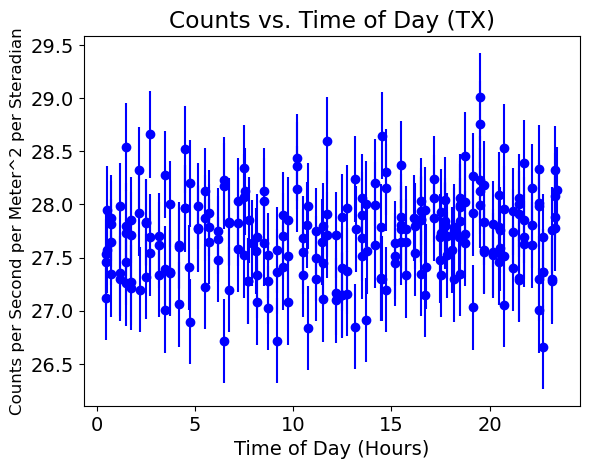

In [28]:
_BINTIME_ = 3600.0 * 1.
## put the count rate in the correct units
FACTOR = (
    _BINTIME_ * 225. / 10000. * 2.094
)  # account for detector area (225/10,000) and acceptance angle (2.094 steradians)

#TX
fnums = ["1", "2", "3", "4"]
allx = np.zeros(0)  # Stores Time of Day
ally = np.zeros(0)  # Stores Counts Rate
allxerr = np.zeros(0)
allyerr = np.zeros(0)
totalDays = 0.0

for num in fnums:
    fname = f"STAR/Data/Ground/TX/{num}.csv"
    cnts, cerr, prvs, prve, tvs, tve, days = getCntsPress(fname, _BINTIME_)

    print(
        f"File: {fname} | Extracted {len(cnts)} bins | Time span: {days:.2f} days"
    )

for num in fnums:
    fname = (
        "STAR/Data/Ground/TX/%s.csv"
        % (num)
    )
    cnts, cerr, prvs, prve, tvs, tve, days = getCntsPress(fname, _BINTIME_)
    totalDays += days

    ## Plot vs Time of Day (tvs)
    plt.errorbar(tvs, cnts / FACTOR, yerr=cerr / FACTOR, xerr=None, fmt="o", color="blue", ecolor="blue")
    allx = np.append(allx, tvs)
    ally = np.append(ally, cnts / FACTOR)
    allxerr = np.append(allxerr, tve)
    allyerr = np.append(allyerr, cerr / FACTOR)
    plt.ylabel("Counts per Second per Meter^2 per Steradian", fontsize = 12)
    plt.xlabel("Time of Day (Hours)")
    plt.title("Counts vs. Time of Day (TX)")

plt.savefig('timeofday-tx.png')


In [47]:
aug_cw=getCosmicWatch_df('STAR/Data/Aug/AxLab_C_003.txt',60,50)

In [48]:
aug_cw

,Pressure,Temp,Timestamp_s,Counts_Per_Second,Rate_Error,Raw_Counts
0,101325.434783,31.827717,80.016709,3.069955,0.226320,184
1,101323.483146,31.871910,140.016709,2.971251,0.222705,178
2,101318.368421,32.047368,200.016709,2.854085,0.218257,171
3,101315.759777,32.189944,260.016709,2.981847,0.222874,179
4,101312.238579,32.263452,320.016709,3.281770,0.233816,197
...,...,...,...,...,...,...
866,101224.443243,28.700000,52040.016709,3.083774,0.226724,185
867,101225.759777,28.768156,52100.016709,2.977961,0.222583,179
868,101230.361582,28.800000,52160.016709,2.940577,0.221027,177
869,101233.657754,28.747594,52220.016709,3.115132,0.227801,187


In [45]:
aug_pil=pd.read_csv('STAR/Data/Aug/Lunar_Eclipse_CosmicWatch_HABPilot_aligned.csv')
aug_pil

,minute,events,coincidences,mean_sipm_mv,event_rate_hz,coinc_rate_hz,altitude_ft,coinc_5min_hz,events_5min_hz,band
0,2026-08-28 03:15:00,193,12,26.770466,3.216667,0.200000,566.690460,0.238889,3.205556,"(0, 10000]"
1,2026-08-28 03:16:00,198,16,29.664646,3.300000,0.266667,567.392997,0.216667,3.175000,"(0, 10000]"
2,2026-08-28 03:17:00,186,15,28.508065,3.100000,0.250000,567.221737,0.226667,3.193333,"(0, 10000]"
3,2026-08-28 03:18:00,185,9,24.863243,3.083333,0.150000,567.050477,0.223333,3.153333,"(0, 10000]"
4,2026-08-28 03:19:00,196,16,27.939286,3.266667,0.266667,566.879218,0.243333,3.163333,"(0, 10000]"
...,...,...,...,...,...,...,...,...,...,...
91,2026-08-28 04:46:00,162,10,28.256173,2.700000,0.166667,99073.300371,0.176667,2.683333,"(90000, 110000]"
92,2026-08-28 04:47:00,172,13,26.537209,2.866667,0.216667,100185.732165,0.193333,2.680000,"(90000, 110000]"
93,2026-08-28 04:48:00,150,8,25.824000,2.500000,0.133333,101298.163959,0.200000,2.900000,"(90000, 110000]"
94,2026-08-28 04:49:00,185,18,23.985946,3.083333,0.300000,102410.595753,0.208333,2.950000,"(90000, 110000]"


In [46]:
aug_cw.head(10)

,Pressure,Temp,Timestamp_s,Counts_Per_Second,Rate_Error,Raw_Counts
0,101325.434783,31.827717,60.016709,3.069955,0.226320,184
1,101323.483146,31.871910,120.016709,2.971251,0.222705,178
2,101318.368421,32.047368,180.016709,2.854085,0.218257,171
3,101315.759777,32.189944,240.016709,2.981847,0.222874,179
4,101312.238579,32.263452,300.016709,3.281770,0.233816,197
5,101311.661017,32.200000,360.016709,2.964292,0.222810,177
6,101311.980769,32.235096,420.016709,3.457036,0.239702,208
7,101314.433333,32.291667,480.016709,3.000012,0.223608,180
8,101314.800000,32.207143,540.016709,3.528513,0.243491,210
9,101319.050000,32.239500,600.016709,3.337673,0.236009,200


In [49]:
X = aug_cw[['Pressure','Temp']]
y = aug_cw['Counts_Per_Second']
gbr_report(X,y)

R² Score: -0.0708
RMSE: 0.2561

--- Feature Importances ---
 Feature  Importance
Pressure    0.575066
    Temp    0.424934


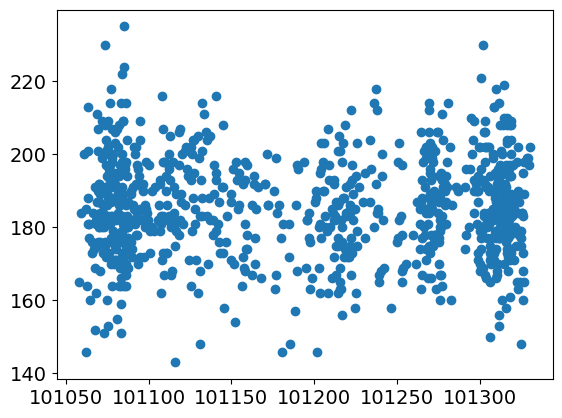

In [56]:
aug_cw = aug_cw.drop(aug_cw['Raw_Counts'].idxmin())
plt.scatter(aug_cw['Pressure'],aug_cw['Raw_Counts'])
plt.savefig('press-counts-minutes.png')